# Milestone 3 — Part 2: Transfer Learning with Pretrained Seq2seq Models

**Task (same as Part 1):** read a MedQuAD question and predict the 384-number MiniLM embedding of its answer (standardised with the training-set scaler). A predicted vector can then be used to *retrieve* the closest known answer.

**Why seq2seq models instead of image CNNs?** VGG19, ResNet and MobileNet were pretrained on photos, while our input is text. We therefore transfer from three pretrained text-to-text (seq2seq) models:

| Short name | Hugging Face ID | Pretrained on |
|---|---|---|
| `flan-t5-small` | `google/flan-t5-small` | General web text + instruction / Q&A tuning |
| `bart-base` | `facebook/bart-base` | General text (denoising) |
| `scifive-base` | `razent/SciFive-base-Pubmed_PMC` | PubMed abstracts + PMC full-text papers (biomedical) |

For steps 1–5 we use each model's **encoder** (the part that reads the question), mean-pool its token outputs and attach a new regression head. At the end we also fine-tune the best model as a full **seq2seq generator** that writes answers.

**Fair comparison with Part 1:** identical data cleaning, identical split (`random_state=42`), identical targets and scaler, identical augmentation. Every model is selected on validation RMSE and evaluated once on the test set with:
- **Test RMSE** (lower is better; predicting the mean gives ≈ 1.0)
- **Top-1 / Top-5 retrieval accuracy and MRR**: for each test question, rank all distinct test answers by cosine similarity to the prediction and check where the true answer lands.

**Runtime:** designed for a Colab T4 GPU (Runtime → Change runtime type → T4 GPU). Steps 1, 3 and 5 are fast; step 2 and the generative section take the most time. Set `USE_AUGMENTATION = False` (section 3) or `GEN_MODEL = "google/flan-t5-small"` (section 13) to shorten the run.

In [1]:
!pip install -q sentencepiece rouge-score sentence-transformers kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# 1. Data Loading, Cleaning, and Splitting (identical to Part 1)

In [2]:
import random, json, copy, gc, re, time, warnings
import numpy as np
import pandas as pd
import kagglehub
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_dir = Path("part2_results")
save_dir.mkdir(exist_ok=True)
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

# ---- Functions copied unchanged from Part 1 ----
def load_data():
  df = pd.read_parquet("hf://datasets/lavita/MedQuAD/data/train-00000-of-00001-e36383d177026d53.parquet")

  return df

def load_data2():
  path = kagglehub.dataset_download("pythonafroz/medquad-medical-question-answer-for-ai-research")
  data_dir = Path(path)
  df = pd.read_csv(data_dir / "medquad.csv")

  return df

def mergeAnswers(df1, df2):
  df3 = df1.copy()
  lookup = (
      df2.loc[df2["answer"].notna(), ["question", "answer"]]
        .drop_duplicates(subset="question")
        .set_index("question")["answer"]
  )
  missing = df3["answer"].isna() | df3["answer"].fillna("").str.strip().eq("")
  df3.loc[missing, "answer"] = df3.loc[missing, "question"].map(lookup)

  return df3

def preprocess(df1, df2):
  # the answer columns has many missing values, so I merged two different published dataset (both are the same but with different sorces) to minimize the losses of info
  df = mergeAnswers(df1, df2)
  # around 15k value in the category column is None, so will fill them with the "Other" Value
  df["category"] = df["category"].fillna("Other")
  #there are some unuseful columns, so I throw it in the trash :), umls_semantic_group values is either disorder or None (unuseful!)
  usefulness_columns = ["document_id", "document_url", "umls_cui", "umls_semantic_types", "umls_semantic_group"]
  df = df.drop(columns = usefulness_columns)
  #if the record does not provide an answer value, it is useless so we will just drop it
  df.dropna(subset = "answer", inplace=True)
  #the merged answers are copies of question/answer pairs we already have, so we drop the duplicates
  df["answer"] = df["answer"].str.strip()
  df = df.drop_duplicates(subset = ["question", "answer"])
  #stratify needs enough records in each question_type ("support groups" has only 1 record)
  counts = df["question_type"].value_counts()
  df = df[df["question_type"].isin(counts[counts >= 10].index)]
  #the kaggle dataset has no synonyms column, and synonyms is not an input to the model, so this step is skipped
  # df = resolving_missing_values_of_synonyms(df, df2)
  return df

def split(df):
  X = df.drop(columns = "answer")
  y = df["answer"]
  stratify_column = df["question_type"]
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = stratify_column, random_state = 42)
  X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, stratify = X_train["question_type"], random_state = 42)

  return X_train, X_test, X_val, y_train, y_test, y_val


df1 = load_data()
df2 = load_data2()
df = preprocess(df1, df2)
print("clean shape:", df.shape)

X_train, X_test, X_val, y_train, y_test, y_val = split(df)
print("train:", len(X_train), " val:", len(X_val), " test:", len(X_test))

Device: cuda | Tesla T4
Using Colab cache for faster access to the 'medquad-medical-question-answer-for-ai-research' dataset.
clean shape: (16358, 8)
train: 10468  val: 2618  test: 3272


# 2. Answer Embedding Targets (identical to Part 1)

The frozen `all-MiniLM-L6-v2` encoder turns every answer into 384 numbers. The scaler is fitted on training answers only.

In [3]:
target_encoder = SentenceTransformer("all-MiniLM-L6-v2", device=str(device))
target_encoder.eval()

def embed_answers(texts):
    return target_encoder.encode(
        list(texts), batch_size=64, show_progress_bar=True, convert_to_numpy=True
    )

y_train_emb = embed_answers(y_train)
y_val_emb = embed_answers(y_val)
y_test_emb = embed_answers(y_test)

y_scaler = StandardScaler().fit(y_train_emb)
y_train_s = y_scaler.transform(y_train_emb).astype(np.float32)
y_val_s = y_scaler.transform(y_val_emb).astype(np.float32)
y_test_s = y_scaler.transform(y_test_emb).astype(np.float32)

print("Targets:", y_train_s.shape, y_val_s.shape, y_test_s.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Batches:   0%|          | 0/164 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Batches:   0%|          | 0/52 [00:00<?, ?it/s]

Targets: (10468, 384) (2618, 384) (3272, 384)


# 3. Training Questions with the Part 1 Augmentation

Same two augmentations as Part 1 (framing and rephrasing). Each augmented question keeps its original answer target. Validation and test questions are never augmented.

In [4]:
# ---- Augmentation functions copied unchanged from Part 1 ----
def augment_framing(question):
    return "Please answer this question: " + str(question).strip()

def augment_rephrasing(question):
    question = str(question).strip()

    # Replace only the opening phrase.
    replacements = [
        (r"^what are the symptoms of\b",
         "Which symptoms are associated with"),

        (r"^what causes\b",
         "What leads to"),

        (r"^what is \(are\)\s+",
         "Could you explain "),

        (r"^what is\b",
         "Could you explain"),

        (r"^what are\b",
         "Could you describe"),
    ]

    for pattern, replacement in replacements:
        if re.search(pattern, question, flags=re.IGNORECASE):
            return re.sub(
                pattern,
                replacement,
                question,
                count=1,
                flags=re.IGNORECASE
            )

    # Preserve unfamiliar question structures.
    return "I would like to know: " + question

USE_AUGMENTATION = True   # set to False to train ~3x faster on the original questions only

train_questions = X_train["question"].tolist()
val_questions = X_val["question"].tolist()
test_questions = X_test["question"].tolist()

if USE_AUGMENTATION:
    fit_questions = (
        train_questions
        + [augment_framing(q) for q in train_questions]
        + [augment_rephrasing(q) for q in train_questions]
    )
    fit_targets = np.concatenate([y_train_s, y_train_s, y_train_s])
else:
    fit_questions = train_questions
    fit_targets = y_train_s

N_ORIG = len(train_questions)   # the first N_ORIG fit rows are the original questions
print("Training questions used for fitting:", len(fit_questions))

Training questions used for fitting: 31404


# 4. Evaluation: RMSE and Answer Retrieval

`retrieval()` turns a predicted (scaled) vector back into MiniLM space and ranks every **distinct** test answer by cosine similarity. Some answers are shared by several questions, so a hit means the top-ranked answer *text* equals the true answer text.

In [5]:
test_answers = pd.Series(y_test.values)
is_first = ~test_answers.duplicated().values
pool_texts = test_answers[is_first].tolist()
pool_index = {t: i for i, t in enumerate(pool_texts)}
true_pool_idx = np.array([pool_index[t] for t in test_answers])
pool_emb = y_test_emb[is_first]
pool_norm = pool_emb / np.linalg.norm(pool_emb, axis=1, keepdims=True)
print("Test questions:", len(test_answers), "| distinct candidate answers:", len(pool_texts))


def rmse(pred, target):
    pred = np.asarray(pred, dtype=np.float64)
    target = np.asarray(target, dtype=np.float64)
    return float(np.sqrt(np.mean((pred - target) ** 2)))


def retrieval(pred_scaled, rows=None):
    rows = np.arange(len(true_pool_idx)) if rows is None else np.asarray(rows)
    raw = y_scaler.inverse_transform(np.asarray(pred_scaled, dtype=np.float64))
    raw = raw / np.clip(np.linalg.norm(raw, axis=1, keepdims=True), 1e-12, None)
    sims = raw @ pool_norm.T
    true_sim = sims[np.arange(len(sims)), true_pool_idx[rows]]
    rank = (sims > true_sim[:, None]).sum(axis=1)          # 0 = true answer ranked first
    return {
        "top1": float((rank < 1).mean()),
        "top5": float((rank < 5).mean()),
        "mrr": float((1.0 / (rank + 1)).mean()),
    }


def test_report(pred_scaled, rows=None):
    target = y_test_s if rows is None else y_test_s[rows]
    return {"test_rmse": rmse(pred_scaled, target), **retrieval(pred_scaled, rows)}


all_results = []

def record(model, method, val_rmse, test_pred, rows=None, **extra):
    row = {"model": model, "method": method, "val_rmse": val_rmse,
           **test_report(test_pred, rows), **extra}
    all_results.append(row)
    print(f"{model} | {method} | val RMSE {val_rmse if val_rmse is None else round(val_rmse, 4)} | "
          f"test RMSE {row['test_rmse']:.4f} | top-1 {row['top1']:.3f} | "
          f"top-5 {row['top5']:.3f} | MRR {row['mrr']:.3f}")
    return row


# Reference point: always predict the average training answer (0 in scaled space).
record("Mean predictor", "Baseline",
       rmse(np.zeros_like(y_val_s), y_val_s), np.zeros_like(y_test_s));

Test questions: 3272 | distinct candidate answers: 3164
Mean predictor | Baseline | val RMSE 0.9982 | test RMSE 0.9997 | top-1 0.000 | top-5 0.002 | MRR 0.003


# 5. Loading the Pretrained Encoders and Replacing the Head

The original prediction head of a seq2seq model is a language-model head that predicts the next word. We drop it (and the decoder) and attach a head that matches our task: **pooled question vector → 384 answer-embedding numbers**.

- `linear` head (steps 1 and 2): a single `Linear(d_model → 384)`.
- `deep` head (step 3): extra layers `LayerNorm → FC 512 → GELU → Dropout → FC 512 → GELU → Dropout → FC 384`.

In [6]:
from transformers import AutoConfig, AutoTokenizer, T5EncoderModel, BartModel
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

MODEL_NAMES = {
    "flan-t5-small": "google/flan-t5-small",
    "bart-base": "facebook/bart-base",
    "scifive-base": "razent/SciFive-base-Pubmed_PMC",
}
MAX_LEN = 64
OUT_DIM = 384


def load_encoder(hf_name):
    model_type = AutoConfig.from_pretrained(hf_name).model_type
    if model_type == "t5":
        encoder = T5EncoderModel.from_pretrained(hf_name)
        blocks = list(encoder.encoder.block)
        final_norms = [encoder.encoder.final_layer_norm]
    elif model_type == "bart":
        encoder = BartModel.from_pretrained(hf_name).get_encoder()
        blocks = list(encoder.layers)
        final_norms = []
    else:
        raise ValueError(f"Unsupported model type: {model_type}")
    return encoder, blocks, final_norms


def make_head(kind, d_model):
    if kind == "linear":
        return nn.Sequential(nn.Linear(d_model, OUT_DIM))
    if kind == "deep":
        return nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 512), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(512, 512), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(512, OUT_DIM),
        )
    raise ValueError(kind)


class EncoderRegressor(nn.Module):
    def __init__(self, hf_name, head_kind):
        super().__init__()
        self.encoder, self.blocks, self.final_norms = load_encoder(hf_name)
        self.d_model = self.encoder.config.d_model
        self.head = make_head(head_kind, self.d_model)

    def pool(self, input_ids, attention_mask):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        return (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)

    def forward(self, input_ids, attention_mask):
        return self.head(self.pool(input_ids, attention_mask))

    def features(self, input_ids, attention_mask):
        # Everything except the final prediction layer (used in step 5).
        return self.head[:-1](self.pool(input_ids, attention_mask))

    def freeze_backbone(self):
        for p in self.encoder.parameters():
            p.requires_grad = False

    def unfreeze_last(self, n=3):
        for module in self.blocks[-n:] + self.final_norms:
            for p in module.parameters():
                p.requires_grad = True


def count_trainable(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


def tokenize_texts(tokenizer, texts):
    enc = tokenizer(list(texts), padding="max_length", truncation=True,
                    max_length=MAX_LEN, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]


def trim(ids, mask):
    # Drop padding columns that no sequence in the batch uses (both tokenizers pad on the right).
    length = int(mask.sum(1).max())
    return ids[:, :length], mask[:, :length]


@torch.no_grad()
def encode_batches(model, ids, mask, mode="pool", batch_size=256):
    model.eval()
    outputs = []
    for i in range(0, len(ids), batch_size):
        a, m = trim(ids[i:i + batch_size], mask[i:i + batch_size])
        a, m = a.to(device), m.to(device)
        fn = {"pool": model.pool, "predict": model.forward, "features": model.features}[mode]
        outputs.append(fn(a, m).float().cpu())
    return torch.cat(outputs)


def free_memory():
    # Call after `del model` so the GPU memory is actually released.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Tokenise every split once per model and cache it.
tokenized = {}
for short, hf_name in MODEL_NAMES.items():
    tok = AutoTokenizer.from_pretrained(hf_name)
    tokenized[short] = {
        "fit": tokenize_texts(tok, fit_questions),
        "train": tokenize_texts(tok, train_questions),
        "val": tokenize_texts(tok, val_questions),
        "test": tokenize_texts(tok, test_questions),
    }
    lengths = tokenized[short]["train"][1].sum(1)
    print(f"{short:14s} vocab {tok.vocab_size:6d} | mean tokens {lengths.float().mean():.1f} | "
          f"truncated {(lengths == MAX_LEN).float().mean():.2%}")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (5 outputs left out)

bart-base      vocab  50265 | mean tokens 14.6 | truncated 0.00%


config.json:   0%|          | 0.00/581 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

scifive-base   vocab  32100 | mean tokens 16.3 | truncated 0.00%


# 6. Training Helpers

- `train_head()` trains a head on **pre-computed** pooled encoder outputs. When the whole backbone is frozen its outputs never change, so we compute them once (steps 1 and 3). This gives exactly the same result as running the frozen encoder every batch, only much faster.
- `train_partial()` trains a model whose last encoder blocks are unfrozen (step 2), using separate learning rates for the pretrained blocks and the new head.

Both use MSE loss, AdamW, early stopping on validation RMSE, and restore the best epoch.

In [7]:
def train_head(head, F_fit, Y_fit, F_val, Y_val, lr, epochs=80, patience=8,
               batch_size=256, weight_decay=1e-4):
    head = head.to(device)
    F_fit, F_val = F_fit.to(device), F_val.to(device)
    Y_fit = torch.as_tensor(Y_fit, device=device)
    Y_val = torch.as_tensor(Y_val, device=device)
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)
    generator = torch.Generator(device="cpu").manual_seed(42)

    best_rmse, best_state, waiting, history = float("inf"), None, 0, []
    for epoch in range(1, epochs + 1):
        head.train()
        order = torch.randperm(len(F_fit), generator=generator).to(device)
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = F.mse_loss(head(F_fit[idx]), Y_fit[idx])
            loss.backward()
            optimizer.step()

        head.eval()
        with torch.no_grad():
            train_rmse = F.mse_loss(head(F_fit[:N_ORIG]), Y_fit[:N_ORIG]).sqrt().item()
            val_rmse = F.mse_loss(head(F_val), Y_val).sqrt().item()
        history.append({"epoch": epoch, "train_rmse": train_rmse, "val_rmse": val_rmse})

        if val_rmse < best_rmse:
            best_rmse, waiting = val_rmse, 0
            best_state = copy.deepcopy(head.state_dict())
        else:
            waiting += 1
            if waiting >= patience:
                break

    head.load_state_dict(best_state)
    return head, best_rmse, pd.DataFrame(history)


def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


def train_partial(model, ids, mask, targets, val_ids, val_mask, lr_encoder, lr_head,
                  epochs, patience=2, batch_size=32, log_name=""):
    encoder_params = [p for p in model.encoder.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW([
        {"params": encoder_params, "lr": lr_encoder},
        {"params": model.head.parameters(), "lr": lr_head},
    ], weight_decay=0.01)
    trainable = encoder_params + list(model.head.parameters())

    loader = DataLoader(TensorDataset(ids, mask, torch.as_tensor(targets)),
                        batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    train_eval = (tokenized_train_sample_ids, tokenized_train_sample_mask)

    best_rmse, best_state, waiting, history = float("inf"), None, 0, []
    for epoch in range(1, epochs + 1):
        model.train()
        start = time.time()
        for a, m, y in loader:
            a, m = trim(a, m)
            a, m, y = a.to(device), m.to(device), y.to(device)
            optimizer.zero_grad()
            loss = F.mse_loss(model(a, m), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            optimizer.step()

        val_rmse = rmse(encode_batches(model, val_ids, val_mask, "predict"), y_val_s)
        train_rmse = rmse(encode_batches(model, *train_eval, "predict"), y_train_s[TRAIN_SAMPLE])
        history.append({"epoch": epoch, "train_rmse": train_rmse, "val_rmse": val_rmse})
        print(f"  {log_name} epoch {epoch}/{epochs} | train RMSE {train_rmse:.4f} | "
              f"val RMSE {val_rmse:.4f} | {time.time() - start:.0f}s", flush=True)

        if val_rmse < best_rmse:
            best_rmse, waiting = val_rmse, 0
            best_state = trainable_state(model)
        else:
            waiting += 1
            if waiting >= patience:
                print("  early stopping")
                break

    model.load_state_dict(best_state, strict=False)
    return model, best_rmse, pd.DataFrame(history)


# Fixed sample of 2,000 original training questions for cheap train-RMSE logging in step 2.
TRAIN_SAMPLE = np.random.RandomState(42).choice(N_ORIG, size=2000, replace=False)
step_runs = []   # one entry per (model, step): used to pick the best model in step 4

# 7. Step 1 — Frozen Backbone, Train Only the New Head

The pretrained encoder is completely frozen; only `Linear(d_model → 384)` is trained. We try three head learning rates and keep the one with the lowest validation RMSE.

In [8]:
HEAD_LRS = [1e-3, 3e-3, 1e-2]
feature_cache = {}
step1_lr_rows = []

for short, hf_name in MODEL_NAMES.items():
    print(f"=== {short} ===")
    model = EncoderRegressor(hf_name, "linear").to(device)
    model.freeze_backbone()
    t = tokenized[short]
    feature_cache[short] = {split: encode_batches(model, *t[split], "pool")
                            for split in ["fit", "val", "test"]}
    Fc = feature_cache[short]
    print(f"encoder parameters (frozen): {sum(p.numel() for p in model.encoder.parameters()):,} | "
          f"pooled feature size: {model.d_model}")

    best = None
    for lr in HEAD_LRS:
        set_seed()
        head = make_head("linear", model.d_model)
        head, val_rmse, history = train_head(head, Fc["fit"], fit_targets, Fc["val"], y_val_s, lr)
        step1_lr_rows.append({"model": short, "head_lr": lr, "best_val_rmse": val_rmse,
                              "epochs_run": len(history)})
        print(f"  head lr {lr:g}: best val RMSE {val_rmse:.4f} ({len(history)} epochs)")
        if best is None or val_rmse < best[0]:
            best = (val_rmse, lr, head, history)

    val_rmse, lr, head, history = best
    print(f"  trainable parameters: {count_trainable(head):,}")
    with torch.no_grad():
        test_pred = head(Fc["test"].to(device)).cpu().numpy()
    record(short, "Step 1: head only", val_rmse, test_pred, lr=lr)

    ckpt = save_dir / f"{short}_step1.pt"
    torch.save({"head": head.state_dict()}, ckpt)
    history.to_csv(save_dir / f"{short}_step1_history.csv", index=False)
    step_runs.append({"model": short, "hf_name": hf_name, "step": 1, "head_kind": "linear",
                      "val_rmse": val_rmse, "lr": lr, "ckpt": str(ckpt)})
    del model
    free_memory()

step1_lrs = pd.DataFrame(step1_lr_rows)
display(step1_lrs)
step1_lrs.to_csv(save_dir / "step1_lr_search.csv", index=False)

=== flan-t5-small ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

encoder parameters (frozen): 35,332,800 | pooled feature size: 512
  head lr 0.001: best val RMSE 0.8398 (80 epochs)
  head lr 0.003: best val RMSE 0.8319 (80 epochs)
  head lr 0.01: best val RMSE 0.8307 (61 epochs)
  trainable parameters: 196,992
flan-t5-small | Step 1: head only | val RMSE 0.8307 | test RMSE 0.8302 | top-1 0.344 | top-5 0.580 | MRR 0.456
=== bart-base ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/99 [00:00<?, ?it/s]

encoder parameters (frozen): 109,628,544 | pooled feature size: 768
  head lr 0.001: best val RMSE 0.7917 (80 epochs)
  head lr 0.003: best val RMSE 0.7928 (41 epochs)
  head lr 0.01: best val RMSE 0.7979 (23 epochs)
  trainable parameters: 295,296
scifive-base | Step 1: head only | val RMSE 0.7917 | test RMSE 0.7896 | top-1 0.495 | top-5 0.739 | MRR 0.609


,model,head_lr,best_val_rmse,epochs_run
0,flan-t5-small,0.001,0.839765,80
1,flan-t5-small,0.003,0.831882,80
2,flan-t5-small,0.010,0.830695,61
3,bart-base,0.001,0.818914,80
4,bart-base,0.003,0.816389,80
5,bart-base,0.010,0.820085,37
6,scifive-base,0.001,0.791696,80
7,scifive-base,0.003,0.792774,41
8,scifive-base,0.010,0.797854,23


# 8. Step 2 — Freeze the Backbone, Train Only the Last 3 Layers

All encoder parameters are frozen except the **last 3 encoder blocks** (plus T5's final layer norm, which normalises their output). The new head is trained too; it starts from the step 1 head so the unfrozen blocks are not disturbed by a random head at the start.

**Choosing the learning rate.** Pretrained blocks need a much smaller learning rate than a new head; too large a rate destroys what they learned. We run a short search (1 epoch on the original training questions) over three encoder learning rates, keep the head at 1e-3, and train the full model with the winner.

In [9]:
ENCODER_LRS = [1e-5, 3e-5, 1e-4]
HEAD_LR_STEP2 = 1e-3
SEARCH_EPOCHS = 1
FULL_EPOCHS = 6

step1_heads = {r["model"]: r for r in step_runs if r["step"] == 1}
step2_lr_rows = []


def build_step2_model(short, hf_name):
    set_seed()
    model = EncoderRegressor(hf_name, "linear")
    model.head.load_state_dict(torch.load(step1_heads[short]["ckpt"])["head"])
    model.freeze_backbone()
    model.unfreeze_last(3)
    return model.to(device)


for short, hf_name in MODEL_NAMES.items():
    print(f"=== {short} ===")
    t = tokenized[short]
    tokenized_train_sample_ids = t["train"][0][TRAIN_SAMPLE]
    tokenized_train_sample_mask = t["train"][1][TRAIN_SAMPLE]

    # Learning-rate search
    best_lr, best_search = None, float("inf")
    for lr in ENCODER_LRS:
        model = build_step2_model(short, hf_name)
        _, val_rmse, _ = train_partial(model, *t["train"], y_train_s, *t["val"],
                                       lr_encoder=lr, lr_head=HEAD_LR_STEP2,
                                       epochs=SEARCH_EPOCHS, log_name=f"lr {lr:g}")
        step2_lr_rows.append({"model": short, "encoder_lr": lr, "val_rmse_after_search": val_rmse})
        if val_rmse < best_search:
            best_lr, best_search = lr, val_rmse
        del model
        free_memory()
    print(f"  selected encoder lr: {best_lr:g}")

    # Full training with the selected learning rate
    model = build_step2_model(short, hf_name)
    print(f"  trainable parameters: {count_trainable(model):,} of "
          f"{sum(p.numel() for p in model.parameters()):,}")
    model, val_rmse, history = train_partial(model, *t["fit"], fit_targets, *t["val"],
                                             lr_encoder=best_lr, lr_head=HEAD_LR_STEP2,
                                             epochs=FULL_EPOCHS, log_name="full")
    test_pred = encode_batches(model, *t["test"], "predict").numpy()
    record(short, "Step 2: last 3 layers", val_rmse, test_pred, lr=best_lr)

    ckpt = save_dir / f"{short}_step2.pt"
    torch.save({"trainable": trainable_state(model)}, ckpt)
    history.to_csv(save_dir / f"{short}_step2_history.csv", index=False)
    step_runs.append({"model": short, "hf_name": hf_name, "step": 2, "head_kind": "linear",
                      "val_rmse": val_rmse, "lr": best_lr, "ckpt": str(ckpt)})
    del model
    free_memory()

step2_lrs = pd.DataFrame(step2_lr_rows)
display(step2_lrs)
step2_lrs.to_csv(save_dir / "step2_lr_search.csv", index=False)

=== flan-t5-small ===


Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

  lr 1e-05 epoch 1/1 | train RMSE 0.8094 | val RMSE 0.8321 | 13s


Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

  lr 3e-05 epoch 1/1 | train RMSE 0.8121 | val RMSE 0.8316 | 13s


Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

... (16 outputs left out)

  lr 0.0001 epoch 1/1 | train RMSE 0.7604 | val RMSE 0.7837 | 37s
  selected encoder lr: 0.0001


Loading weights:   0%|          | 0/99 [00:00<?, ?it/s]

  trainable parameters: 21,534,336 of 109,923,840
  full epoch 1/6 | train RMSE 0.7495 | val RMSE 0.7750 | 101s
  full epoch 2/6 | train RMSE 0.7352 | val RMSE 0.7647 | 101s
  full epoch 3/6 | train RMSE 0.7239 | val RMSE 0.7579 | 101s
  full epoch 4/6 | train RMSE 0.7130 | val RMSE 0.7520 | 101s
  full epoch 5/6 | train RMSE 0.7035 | val RMSE 0.7465 | 101s
  full epoch 6/6 | train RMSE 0.6938 | val RMSE 0.7425 | 101s
scifive-base | Step 2: last 3 layers | val RMSE 0.7425 | test RMSE 0.7392 | top-1 0.559 | top-5 0.770 | MRR 0.656


,model,encoder_lr,val_rmse_after_search
0,flan-t5-small,0.00001,0.832072
1,flan-t5-small,0.00003,0.831598
2,flan-t5-small,0.00010,0.830800
3,bart-base,0.00001,0.824516
4,bart-base,0.00003,0.824116
5,bart-base,0.00010,0.820337
6,scifive-base,0.00001,0.790903
7,scifive-base,0.00003,0.788586
8,scifive-base,0.00010,0.783706


# 9. Step 3 — Add New Layers on Top of the Frozen Backbone

The pretrained encoder stays frozen; we add a deeper head (LayerNorm, two FC-512 layers with GELU and dropout 0.3, then the output layer) and train only these new layers.

In [10]:
DEEP_LRS = [3e-4, 1e-3]
step3_lr_rows = []

for short, hf_name in MODEL_NAMES.items():
    print(f"=== {short} ===")
    Fc = feature_cache[short]
    d_model = Fc["fit"].shape[1]
    best = None
    for lr in DEEP_LRS:
        set_seed()
        head = make_head("deep", d_model)
        head, val_rmse, history = train_head(head, Fc["fit"], fit_targets, Fc["val"], y_val_s, lr)
        step3_lr_rows.append({"model": short, "lr": lr, "best_val_rmse": val_rmse,
                              "epochs_run": len(history)})
        print(f"  lr {lr:g}: best val RMSE {val_rmse:.4f} ({len(history)} epochs)")
        if best is None or val_rmse < best[0]:
            best = (val_rmse, lr, head, history)

    val_rmse, lr, head, history = best
    print(f"  trainable parameters: {count_trainable(head):,}")
    with torch.no_grad():
        head.eval()
        test_pred = head(Fc["test"].to(device)).cpu().numpy()
    record(short, "Step 3: extra layers", val_rmse, test_pred, lr=lr)

    ckpt = save_dir / f"{short}_step3.pt"
    torch.save({"head": head.state_dict()}, ckpt)
    history.to_csv(save_dir / f"{short}_step3_history.csv", index=False)
    step_runs.append({"model": short, "hf_name": hf_name, "step": 3, "head_kind": "deep",
                      "val_rmse": val_rmse, "lr": lr, "ckpt": str(ckpt)})

step3_lrs = pd.DataFrame(step3_lr_rows)
display(step3_lrs)
step3_lrs.to_csv(save_dir / "step3_lr_search.csv", index=False)

=== flan-t5-small ===
  lr 0.0003: best val RMSE 0.7557 (80 epochs)
  lr 0.001: best val RMSE 0.7537 (77 epochs)
  trainable parameters: 723,328
flan-t5-small | Step 3: extra layers | val RMSE 0.7537 | test RMSE 0.7518 | top-1 0.446 | top-5 0.681 | MRR 0.555
=== bart-base ===
  lr 0.0003: best val RMSE 0.7493 (80 epochs)
  lr 0.001: best val RMSE 0.7491 (72 epochs)
  trainable parameters: 854,912
bart-base | Step 3: extra layers | val RMSE 0.7491 | test RMSE 0.7485 | top-1 0.464 | top-5 0.689 | MRR 0.569
=== scifive-base ===
  lr 0.0003: best val RMSE 0.7345 (80 epochs)
  lr 0.001: best val RMSE 0.7348 (72 epochs)
  trainable parameters: 854,912
scifive-base | Step 3: extra layers | val RMSE 0.7345 | test RMSE 0.7314 | top-1 0.522 | top-5 0.748 | MRR 0.628


,model,lr,best_val_rmse,epochs_run
0,flan-t5-small,0.0003,0.755748,80
1,flan-t5-small,0.0010,0.753699,77
2,bart-base,0.0003,0.749281,80
3,bart-base,0.0010,0.749112,72
4,scifive-base,0.0003,0.734533,80
5,scifive-base,0.0010,0.734831,72


method,Step 1: head only,Step 2: last 3 layers,Step 3: extra layers
model,,,
bart-base,0.8173,0.7230,0.7485
flan-t5-small,0.8302,0.7943,0.7518
scifive-base,0.7896,0.7392,0.7314


,model,method,val_rmse,test_rmse,top1,top5,mrr,lr
0,flan-t5-small,Step 1: head only,0.8307,0.8302,0.3438,0.5801,0.4563,0.0100
1,bart-base,Step 1: head only,0.8164,0.8173,0.4312,0.6699,0.5426,0.0030
2,scifive-base,Step 1: head only,0.7917,0.7896,0.4954,0.7393,0.6087,0.0010
3,flan-t5-small,Step 2: last 3 layers,0.7951,0.7943,0.3551,0.5874,0.4656,0.0001
4,bart-base,Step 2: last 3 layers,0.7234,0.7230,0.6510,0.8380,0.7373,0.0001
5,scifive-base,Step 2: last 3 layers,0.7425,0.7392,0.5590,0.7699,0.6565,0.0001
6,flan-t5-small,Step 3: extra layers,0.7537,0.7518,0.4459,0.6809,0.5551,0.0010
7,bart-base,Step 3: extra layers,0.7491,0.7485,0.4639,0.6892,0.5685,0.0010
8,scifive-base,Step 3: extra layers,0.7345,0.7314,0.5220,0.7476,0.6277,0.0003


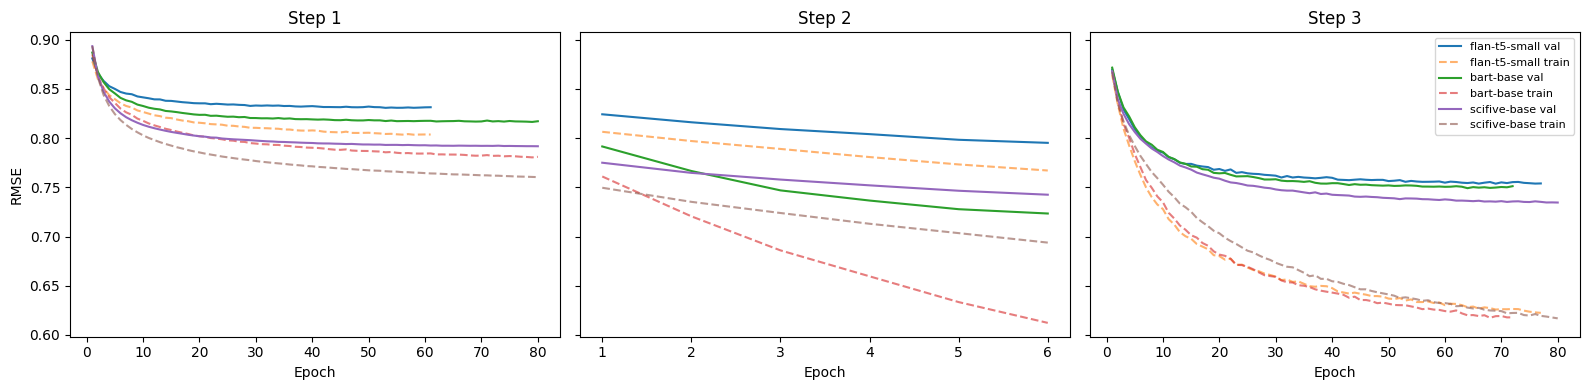

In [11]:
# Summary of steps 1-3 and learning curves
steps_table = pd.DataFrame([r for r in all_results if r["method"].startswith("Step")])
display(steps_table.pivot(index="model", columns="method", values="test_rmse").round(4))
display(steps_table.round(4))
steps_table.to_csv(save_dir / "steps_1_3_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, step in zip(axes, [1, 2, 3]):
    for short in MODEL_NAMES:
        h = pd.read_csv(save_dir / f"{short}_step{step}_history.csv")
        ax.plot(h["epoch"], h["val_rmse"], label=f"{short} val")
        ax.plot(h["epoch"], h["train_rmse"], "--", alpha=0.6, label=f"{short} train")
    ax.set_title(f"Step {step}")
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("RMSE")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(save_dir / "steps_learning_curves.png", dpi=150)
plt.show()

# 10. Step 4 — Save the Best-Performing Model

The best (model, step) pair is chosen by **validation** RMSE, not test RMSE, so the test set stays untouched by model selection. We rebuild it, save the full weights, tokenizer and settings, then reload it from disk to confirm the saved copy reproduces the same validation score.

In [12]:
def rebuild(run):
    model = EncoderRegressor(run["hf_name"], run["head_kind"])
    ckpt = torch.load(run["ckpt"])
    if run["step"] == 2:
        model.load_state_dict(ckpt["trainable"], strict=False)
    else:
        model.head.load_state_dict(ckpt["head"])
    return model.to(device).eval()


best_run = min(step_runs, key=lambda r: r["val_rmse"])
print("Best model:", best_run["model"], "| step", best_run["step"],
      "| val RMSE", round(best_run["val_rmse"], 4))

best_dir = save_dir / "best_model"
best_dir.mkdir(exist_ok=True)
best_model = rebuild(best_run)
torch.save(best_model.state_dict(), best_dir / "model.pt")
AutoTokenizer.from_pretrained(best_run["hf_name"]).save_pretrained(best_dir)
best_info = {**best_run, "max_len": MAX_LEN, "out_dim": OUT_DIM, "pooling": "mean",
             "answer_encoder": "all-MiniLM-L6-v2",
             "target_mean": y_scaler.mean_.tolist(), "target_scale": y_scaler.scale_.tolist()}
with open(best_dir / "model_info.json", "w") as f:
    json.dump(best_info, f, indent=2)

# Reload from disk and verify
reloaded = EncoderRegressor(best_info["hf_name"], best_info["head_kind"])
reloaded.load_state_dict(torch.load(best_dir / "model.pt"))
reloaded = reloaded.to(device).eval()
t = tokenized[best_info["model"]]
print("Reloaded val RMSE:", round(rmse(encode_batches(reloaded, *t["val"], "predict"), y_val_s), 4))
del best_model
free_memory()

Best model: bart-base | step 2 | val RMSE 0.7234


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Reloaded val RMSE: 0.7234


# 11. Step 5 — Best Model as a Feature Extractor + Classical ML

We cut off the final prediction layer of the saved model and use what remains as a fixed feature extractor (for a linear head this is the pooled encoder output; for the deep head it is the 512-d output of its last hidden layer). The features feed four classical regressors:

| Model | Notes |
|---|---|
| Ridge regression | Natively predicts all 384 outputs; `alpha` tuned on validation |
| k-Nearest Neighbours | Averages the answer vectors of the most similar training questions (cosine distance) |
| Linear SVM (LinearSVR) | One SVR per output, so we predict the top 64 PCA components of the target and map back to 384 dimensions |
| Random Forest | Multi-output trees, also on the 64 PCA target components |

Classical models are fitted on the original 10,468 training questions (augmented copies are near-duplicates and would only slow them down). All hyperparameters are chosen on validation RMSE.

In [13]:
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

t = tokenized[best_info["model"]]
F_tr = encode_batches(reloaded, *t["train"], "features").numpy()
F_va = encode_batches(reloaded, *t["val"], "features").numpy()
F_te = encode_batches(reloaded, *t["test"], "features").numpy()
print("Feature shape:", F_tr.shape)
del reloaded
free_memory()

feat_scaler = StandardScaler().fit(F_tr)
S_tr, S_va, S_te = (feat_scaler.transform(x) for x in (F_tr, F_va, F_te))

pca_y = PCA(n_components=64, random_state=42).fit(y_train_s)
Yp_tr = pca_y.transform(y_train_s)
print(f"Target PCA keeps {pca_y.explained_variance_ratio_.sum():.1%} of variance | "
      f"best possible test RMSE with 64 components: "
      f"{rmse(pca_y.inverse_transform(pca_y.transform(y_test_s)), y_test_s):.4f}")

ml_search = []

def tune(name, candidates, fit_predict):
    best = None
    for params in candidates:
        start = time.time()
        val_pred, test_pred = fit_predict(**params)
        val_rmse = rmse(val_pred, y_val_s)
        ml_search.append({"model": name, **params, "val_rmse": val_rmse})
        print(f"  {name} {params}: val RMSE {val_rmse:.4f} ({time.time() - start:.0f}s)")
        if best is None or val_rmse < best[0]:
            best = (val_rmse, params, test_pred)
    val_rmse, params, test_pred = best
    record(f"{best_info['model']} features + {name}", "Step 5: feature extractor",
           val_rmse, test_pred, params=str(params))


def ridge_fp(alpha):
    m = Ridge(alpha=alpha).fit(S_tr, y_train_s)
    return m.predict(S_va), m.predict(S_te)

def knn_fp(k):
    m = KNeighborsRegressor(n_neighbors=k, weights="distance", metric="cosine",
                            algorithm="brute", n_jobs=-1).fit(F_tr, y_train_s)
    return m.predict(F_va), m.predict(F_te)

def svr_fp(C):
    m = MultiOutputRegressor(LinearSVR(C=C, epsilon=0.0, max_iter=5000, random_state=42),
                             n_jobs=-1).fit(S_tr, Yp_tr)
    return pca_y.inverse_transform(m.predict(S_va)), pca_y.inverse_transform(m.predict(S_te))

def rf_fp(min_samples_leaf):
    m = RandomForestRegressor(n_estimators=200, max_features="sqrt",
                              min_samples_leaf=min_samples_leaf, n_jobs=-1,
                              random_state=42).fit(F_tr, Yp_tr)
    return pca_y.inverse_transform(m.predict(F_va)), pca_y.inverse_transform(m.predict(F_te))

tune("Ridge", [{"alpha": a} for a in [1, 10, 100, 1000]], ridge_fp)
tune("KNN", [{"k": k} for k in [5, 10, 20, 40]], knn_fp)
tune("Linear SVM", [{"C": c} for c in [0.01, 0.1]], svr_fp)
tune("Random Forest", [{"min_samples_leaf": s} for s in [2, 5]], rf_fp)

pd.DataFrame(ml_search).to_csv(save_dir / "step5_hyperparameter_search.csv", index=False)
display(pd.DataFrame([r for r in all_results if r["method"].startswith("Step 5")]).round(4))

Feature shape: (10468, 768)
Target PCA keeps 68.2% of variance | best possible test RMSE with 64 components: 0.5656
  Ridge {'alpha': 1}: val RMSE 0.7089 (0s)
  Ridge {'alpha': 10}: val RMSE 0.7087 (0s)
  Ridge {'alpha': 100}: val RMSE 0.7065 (0s)
  Ridge {'alpha': 1000}: val RMSE 0.7008 (0s)
bart-base features + Ridge | Step 5: feature extractor | val RMSE 0.7008 | test RMSE 0.7009 | top-1 0.669 | top-5 0.845 | MRR 0.752
  KNN {'k': 5}: val RMSE 0.7593 (3s)
  KNN {'k': 10}: val RMSE 0.7425 (2s)
  KNN {'k': 20}: val RMSE 0.7452 (3s)
  KNN {'k': 40}: val RMSE 0.7590 (3s)
bart-base features + KNN | Step 5: feature extractor | val RMSE 0.7425 | test RMSE 0.7427 | top-1 0.469 | top-5 0.762 | MRR 0.599
  Linear SVM {'C': 0.01}: val RMSE 0.7619 (136s)
  Linear SVM {'C': 0.1}: val RMSE 0.7633 (901s)
bart-base features + Linear SVM | Step 5: feature extractor | val RMSE 0.7619 | test RMSE 0.7611 | top-1 0.551 | top-5 0.764 | MRR 0.649
  Random Forest {'min_samples_leaf': 2}: val RMSE 0.8632 (1

,model,method,val_rmse,test_rmse,top1,top5,mrr,params
0,bart-base features + Ridge,Step 5: feature extractor,0.7008,0.7009,0.6693,0.8454,0.7519,{'alpha': 1000}
1,bart-base features + KNN,Step 5: feature extractor,0.7425,0.7427,0.4691,0.7619,0.5986,{'k': 10}
2,bart-base features + Linear SVM,Step 5: feature extractor,0.7619,0.7611,0.5510,0.7644,0.6491,{'C': 0.01}
3,bart-base features + Random Forest,Step 5: feature extractor,0.8632,0.8593,0.0987,0.1999,0.1549,{'min_samples_leaf': 2}


# 12. Step 6 — Evalution to All Things :)

A) Pretrained models x training strategies (test set)


,model,method,lr,val_rmse,test_rmse,top1,top5,mrr
0,flan-t5-small,Step 1: head only,0.0100,0.8307,0.8302,0.3438,0.5801,0.4563
1,flan-t5-small,Step 2: last 3 layers,0.0001,0.7951,0.7943,0.3551,0.5874,0.4656
2,flan-t5-small,Step 3: extra layers,0.0010,0.7537,0.7518,0.4459,0.6809,0.5551
3,bart-base,Step 1: head only,0.0030,0.8164,0.8173,0.4312,0.6699,0.5426
4,bart-base,Step 2: last 3 layers,0.0001,0.7234,0.7230,0.6510,0.8380,0.7373
5,bart-base,Step 3: extra layers,0.0010,0.7491,0.7485,0.4639,0.6892,0.5685
6,scifive-base,Step 1: head only,0.0010,0.7917,0.7896,0.4954,0.7393,0.6087
7,scifive-base,Step 2: last 3 layers,0.0001,0.7425,0.7392,0.5590,0.7699,0.6565
8,scifive-base,Step 3: extra layers,0.0003,0.7345,0.7314,0.5220,0.7476,0.6277


Test RMSE (lower is better)


method,Step 1: head only,Step 2: last 3 layers,Step 3: extra layers
model,,,
flan-t5-small,0.8302,0.7943,0.7518
bart-base,0.8173,0.7230,0.7485
scifive-base,0.7896,0.7392,0.7314


Top-1 retrieval accuracy (higher is better)


method,Step 1: head only,Step 2: last 3 layers,Step 3: extra layers
model,,,
flan-t5-small,0.3438,0.3551,0.4459
bart-base,0.4312,0.6510,0.4639
scifive-base,0.4954,0.5590,0.5220


... (2 outputs left out)

B) Feature extractor = bart-base (step 2) + classical ML


,algorithm,params,val_rmse,test_rmse,top1,top5,mrr
0,Ridge,{'alpha': 1000},0.7008,0.7009,0.6693,0.8454,0.7519
1,"Neural head (step 2, reference)",-,0.7234,0.7230,0.6510,0.8380,0.7373
2,KNN,{'k': 10},0.7425,0.7427,0.4691,0.7619,0.5986
3,Linear SVM,{'C': 0.01},0.7619,0.7611,0.5510,0.7644,0.6491
4,Random Forest,{'min_samples_leaf': 2},0.8632,0.8593,0.0987,0.1999,0.1549


C) Overall Part 2 ranking (by test RMSE)


,name,val_rmse,test_rmse,top1,top5,mrr
1,bart-base features | Ridge,0.7008,0.7009,0.6693,0.8454,0.7519
2,bart-base | Step 2: last 3 layers,0.7234,0.7230,0.6510,0.8380,0.7373
3,scifive-base | Step 3: extra layers,0.7345,0.7314,0.5220,0.7476,0.6277
4,scifive-base | Step 2: last 3 layers,0.7425,0.7392,0.5590,0.7699,0.6565
5,bart-base features | KNN,0.7425,0.7427,0.4691,0.7619,0.5986
6,bart-base | Step 3: extra layers,0.7491,0.7485,0.4639,0.6892,0.5685
7,flan-t5-small | Step 3: extra layers,0.7537,0.7518,0.4459,0.6809,0.5551
8,bart-base features | Linear SVM,0.7619,0.7611,0.5510,0.7644,0.6491
9,scifive-base | Step 1: head only,0.7917,0.7896,0.4954,0.7393,0.6087
10,flan-t5-small | Step 2: last 3 layers,0.7951,0.7943,0.3551,0.5874,0.4656


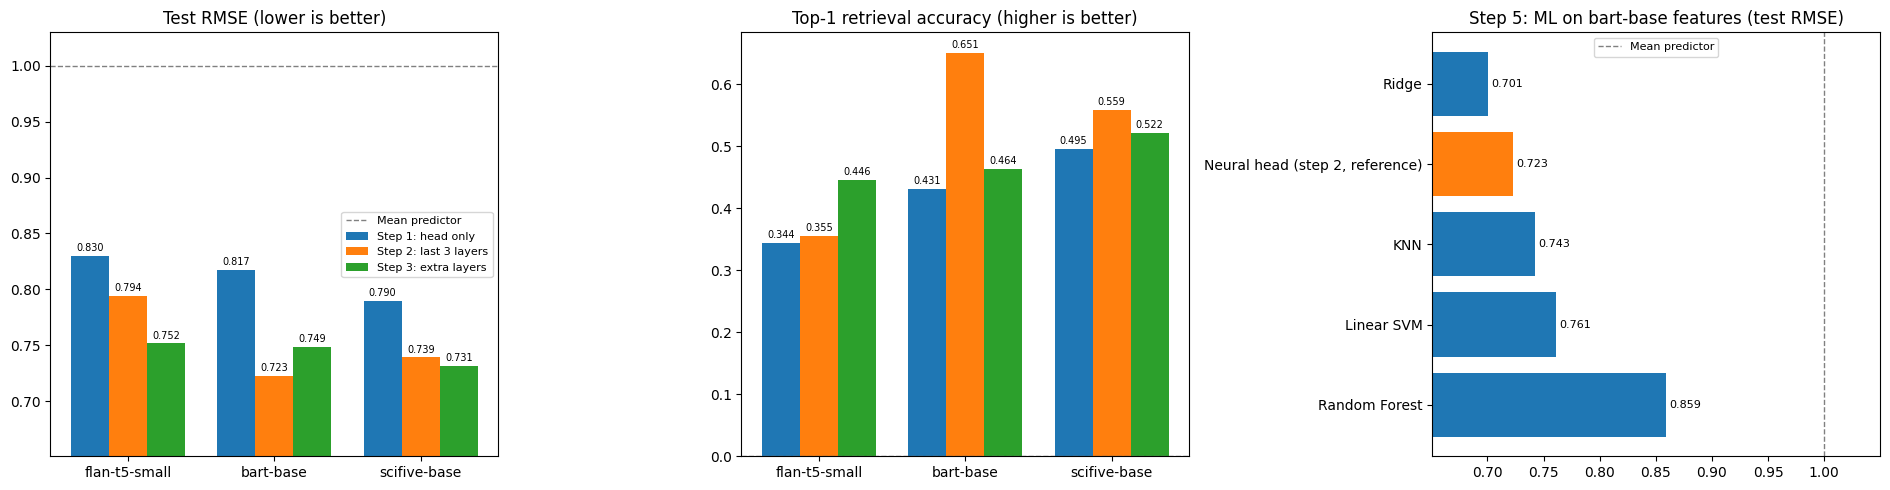

Summary
- Mean-predictor baseline: test RMSE 0.9997, top-1 0.000
- Best Part 2 result: bart-base features | Ridge -> test RMSE 0.7009, top-1 0.669, top-5 0.845
- flan-t5-small: head only 0.8302 -> last 3 layers 0.7943 -> extra layers 0.7518
- bart-base: head only 0.8173 -> last 3 layers 0.7230 -> extra layers 0.7485
- scifive-base: head only 0.7896 -> last 3 layers 0.7392 -> extra layers 0.7314
- Best ML algorithm on extracted features: Ridge (test RMSE 0.7009) vs neural head 0.7230


In [15]:
# ============================================================
# Final Evaluation of Part 2
# ============================================================
res = pd.DataFrame(all_results)
metrics = ["val_rmse", "test_rmse", "top1", "top5", "mrr"]
baseline = res[res["method"] == "Baseline"].iloc[0]

# ---------- (a) Three pretrained models x three fine-tuning strategies ----------
steps = res[res["method"].str.startswith(("Step 1", "Step 2", "Step 3"))].copy()
step_order = ["Step 1: head only", "Step 2: last 3 layers", "Step 3: extra layers"]
model_order = list(MODEL_NAMES)
steps["method"] = pd.Categorical(steps["method"], step_order, ordered=True)
steps["model"] = pd.Categorical(steps["model"], model_order, ordered=True)
steps = steps.sort_values(["model", "method"])

print("=" * 70)
print("A) Pretrained models x training strategies (test set)")
print("=" * 70)
display(steps[["model", "method", "lr"] + metrics].round(4).reset_index(drop=True))

for metric, title in [("test_rmse", "Test RMSE (lower is better)"),
                      ("top1", "Top-1 retrieval accuracy (higher is better)")]:
    print(title)
    display(steps.pivot_table(index="model", columns="method", values=metric,
                              observed=False).round(4))

best_per_model = steps.loc[steps.groupby("model", observed=True)["val_rmse"].idxmin()]
print("Best strategy for each model (chosen by validation RMSE):")
display(best_per_model[["model", "method", "val_rmse", "test_rmse", "top1", "top5"]]
        .round(4).reset_index(drop=True))

# ---------- (b) Best model as feature extractor + 4 ML algorithms ----------
ml = res[res["method"].str.startswith("Step 5")].copy()
ml["algorithm"] = ml["model"].str.split(" + ", regex=False).str[-1]
best_neural = steps[(steps["model"] == best_run["model"]) &
                    (steps["method"].str.startswith(f"Step {best_run['step']}"))].iloc[0]

print("=" * 70)
print(f"B) Feature extractor = {best_run['model']} (step {best_run['step']}) + classical ML")
print("=" * 70)
ml_table = pd.concat([
    ml[["algorithm", "params"] + metrics],
    pd.DataFrame([{"algorithm": f"Neural head (step {best_run['step']}, reference)",
                   "params": "-", **{m: best_neural[m] for m in metrics}}]),
]).sort_values("test_rmse").reset_index(drop=True)
display(ml_table.round(4))

# ---------- (c) Overall ranking of everything in Part 2 ----------
part2 = pd.concat([
    steps.assign(name=steps["model"].astype(str) + " | " + steps["method"].astype(str)),
    ml.assign(name=best_run["model"] + " features | " + ml["algorithm"]),
])[["name"] + metrics].sort_values("test_rmse").reset_index(drop=True)
part2.index += 1
print("=" * 70)
print("C) Overall Part 2 ranking (by test RMSE)")
print("=" * 70)
display(part2.round(4))

# ---------- Plots ----------
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
x = np.arange(len(model_order))
width = 0.26
for ax, metric, label in [(axes[0], "test_rmse", "Test RMSE (lower is better)"),
                          (axes[1], "top1", "Top-1 retrieval accuracy (higher is better)")]:
    for i, step in enumerate(step_order):
        vals = [steps[(steps["model"] == m) & (steps["method"] == step)][metric].iloc[0]
                for m in model_order]
        bars = ax.bar(x + (i - 1) * width, vals, width, label=step)
        ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
    ax.axhline(baseline[metric], color="gray", ls="--", lw=1, label="Mean predictor")
    ax.set_xticks(x, model_order)
    ax.set_title(label)
    if metric == "test_rmse":
        ax.set_ylim(min(steps[metric].min(), ml[metric].min()) - 0.05, baseline[metric] + 0.03)
axes[0].legend(fontsize=8)

ax = axes[2]
plot_ml = ml_table.sort_values("test_rmse", ascending=False)
colors = ["tab:orange" if a.startswith("Neural") else "tab:blue" for a in plot_ml["algorithm"]]
bars = ax.barh(plot_ml["algorithm"], plot_ml["test_rmse"], color=colors)
ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.axvline(baseline["test_rmse"], color="gray", ls="--", lw=1, label="Mean predictor")
ax.set_xlim(plot_ml["test_rmse"].min() - 0.05, baseline["test_rmse"] + 0.05)
ax.set_title(f"Step 5: ML on {best_run['model']} features (test RMSE)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(save_dir / "part2_final_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Save and summarise ----------
steps.to_csv(save_dir / "part2_eval_steps.csv", index=False)
ml_table.to_csv(save_dir / "part2_eval_ml.csv", index=False)
part2.to_csv(save_dir / "part2_eval_ranking.csv", index_label="rank")

best_overall = part2.iloc[0]
best_ml = ml.loc[ml["test_rmse"].idxmin()]
gain = steps.pivot_table(index="model", columns="method", values="test_rmse", observed=False)
print("Summary")
print(f"- Mean-predictor baseline: test RMSE {baseline['test_rmse']:.4f}, top-1 {baseline['top1']:.3f}")
print(f"- Best Part 2 result: {best_overall['name']} -> test RMSE {best_overall['test_rmse']:.4f}, "
      f"top-1 {best_overall['top1']:.3f}, top-5 {best_overall['top5']:.3f}")
for m in model_order:
    print(f"- {m}: head only {gain.loc[m, step_order[0]]:.4f} -> last 3 layers "
          f"{gain.loc[m, step_order[1]]:.4f} -> extra layers {gain.loc[m, step_order[2]]:.4f}")
print(f"- Best ML algorithm on extracted features: {best_ml['algorithm']} "
      f"(test RMSE {best_ml['test_rmse']:.4f}) vs neural head {best_neural['test_rmse']:.4f}")